In [1]:
import os
import numpy as np
from matplotlib import pyplot as plt, colormaps
import tifffile

In [2]:
obj = tifffile.imread("./obj_phase_roi_Niter120.tiff")
obj.shape

(30, 755, 755)

In [25]:
ROI_LENGTH_A = 0.36 * 512
PIXEL_SIZE_A = ROI_LENGTH_A / obj.shape[-1]
print(f"Pixel size: {PIXEL_SIZE_A} Angstrom")
LAYER_DISTANCE_A = 10

Pixel size: 0.24413245033112582 Angstrom


## Task 1 — estimate and remove the global column tilt

Successive $z$ slices are registered with sub-pixel phase correlation after removing the slowly varying background and tapering the image edges.  The cumulative registration shifts are fitted by a straight line; its slope is the global correction vector per slice.  The physical column drift is the negative of that vector.

The TIFF does not contain a physical $z$ spacing, so the result below is reported in lateral pixels per slice.  The in-plane azimuth uses image coordinates: $+x$ is right, $+y$ is down, and angles increase clockwise.

In [27]:
from scipy.ndimage import gaussian_filter, shift as ndi_shift
from scipy.signal.windows import tukey
from skimage.registration import phase_cross_correlation


def estimate_global_tilt(volume, upsample_factor=20, highpass_sigma=6.0):
    """Return the global alignment shift (dy, dx) per z slice."""
    stack = np.asarray(volume, dtype=np.float32)
    if stack.ndim != 3 or stack.shape[0] < 2:
        raise ValueError("volume must have shape (z, y, x) with at least two slices")

    # Keep atom-scale contrast and suppress edge discontinuities before FFT
    # registration.  Registering neighbours avoids lattice-period ambiguity.
    highpass = stack - gaussian_filter(
        stack, sigma=(0, highpass_sigma, highpass_sigma)
    )
    edge_window = np.outer(
        tukey(stack.shape[1], alpha=0.2),
        tukey(stack.shape[2], alpha=0.2),
    ).astype(np.float32)
    registration_stack = highpass * edge_window[None, :, :]

    step_shifts = np.array(
        [
            phase_cross_correlation(
                registration_stack[z - 1],
                registration_stack[z],
                upsample_factor=upsample_factor,
                normalization=None,
            )[0]
            for z in range(1, stack.shape[0])
        ]
    )

    cumulative_shifts = np.vstack(
        (np.zeros(2), np.cumsum(step_shifts, axis=0))
    )
    z_coordinates = np.arange(stack.shape[0], dtype=float)
    alignment_per_slice = np.array(
        [
            np.polyfit(z_coordinates, cumulative_shifts[:, component], 1)[0]
            for component in range(2)
        ]
    )
    fitted_shifts = (
        z_coordinates - z_coordinates.mean()
    )[:, None] * alignment_per_slice
    return alignment_per_slice, fitted_shifts, step_shifts, cumulative_shifts


def align_and_crop(volume, fitted_shifts):
    """Apply (dy, dx) shifts and crop to the overlap shared by all slices."""
    stack = np.asarray(volume, dtype=np.float32)
    aligned = np.stack(
        [
            ndi_shift(
                stack[z],
                shift=tuple(fitted_shifts[z]),
                order=3,
                mode="constant",
                cval=0.0,
                prefilter=True,
            )
            for z in range(stack.shape[0])
        ]
    )

    dy, dx = fitted_shifts.T
    y0 = max(0, int(np.ceil(dy.max())))
    y1 = min(stack.shape[1], stack.shape[1] + int(np.floor(dy.min())))
    x0 = max(0, int(np.ceil(dx.max())))
    x1 = min(stack.shape[2], stack.shape[2] + int(np.floor(dx.min())))
    if y1 <= y0 or x1 <= x0:
        raise ValueError("estimated shifts leave no common image area")
    return aligned[:, y0:y1, x0:x1], (slice(y0, y1), slice(x0, x1))


alignment_dy_dx, fitted_shifts, step_shifts, cumulative_shifts = \
    estimate_global_tilt(obj)
fixed_stack, overlap_crop = align_and_crop(obj, fitted_shifts)
fixed_image = fixed_stack.sum(axis=0)

# A shift aligns the current slice to the preceding slice, so the actual
# movement of a column as z increases has the opposite sign.
tilt_dy_dx = -alignment_dy_dx
tilt_magnitude = np.hypot(*tilt_dy_dx)
tilt_azimuth = np.degrees(np.arctan2(tilt_dy_dx[0], tilt_dy_dx[1])) % 360
tilt_axis = tilt_azimuth % 180
total_tilt_dy_dx = tilt_dy_dx * (obj.shape[0] - 1)

print(f"Alignment correction (dy, dx): {alignment_dy_dx} pixels/slice = {alignment_dy_dx * PIXEL_SIZE_A / LAYER_DISTANCE_A * 1000} mrad")
print(f"Column drift (dy, dx):         {tilt_dy_dx} pixels/slice = {tilt_dy_dx * PIXEL_SIZE_A / LAYER_DISTANCE_A * 1000} mrad")
print(f"Drift magnitude:               {tilt_magnitude:.4f} pixels/slice")
print(f"Directed azimuth:              {tilt_azimuth:.2f}° from +x")
print(f"Undirected tilt axis:          {tilt_axis:.2f}° from +x")
print(f"Drift over the full stack:     {total_tilt_dy_dx} pixels = {total_tilt_dy_dx * PIXEL_SIZE_A} Angstrom")
print(f"Overlap crop (y, x):           {overlap_crop}")
print(f"fixed_image.shape:             {fixed_image.shape}")

# Return a reusable image variable and an on-disk float32 TIFF.
fixed_image_path = "fixed_cropped_projection.tiff"
tifffile.imwrite(fixed_image_path, fixed_stack.astype(np.float32))
print(f"Saved: {fixed_image_path}")

Alignment correction (dy, dx): [0.19235818 0.05482759] pixels/slice = [4.69608743 1.33851936] mrad
Column drift (dy, dx):         [-0.19235818 -0.05482759] pixels/slice = [-4.69608743 -1.33851936] mrad
Drift magnitude:               0.2000 pixels/slice
Directed azimuth:              254.09° from +x
Undirected tilt axis:          74.09° from +x
Drift over the full stack:     [-5.57838727 -1.59000007] pixels = [-1.36186535 -0.38817061] Angstrom
Overlap crop (y, x):           (slice(3, 752, None), slice(1, 754, None))
fixed_image.shape:             (749, 753)
Saved: fixed_cropped_projection.tiff


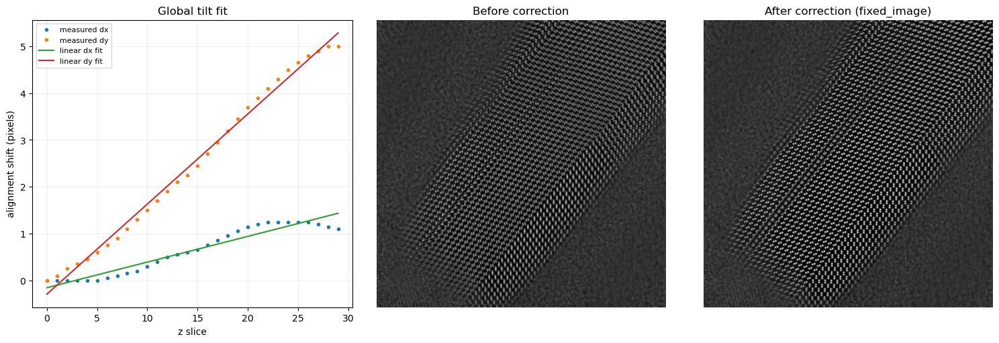

In [4]:
# Registration diagnostic and before/after comparison.
z_coordinates = np.arange(obj.shape[0])
fitted_path = (
    z_coordinates[:, None] * alignment_dy_dx
    + (cumulative_shifts - z_coordinates[:, None] * alignment_dy_dx).mean(axis=0)
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
axes[0].plot(z_coordinates, cumulative_shifts[:, 1], "o", ms=3, label="measured dx")
axes[0].plot(z_coordinates, cumulative_shifts[:, 0], "o", ms=3, label="measured dy")
axes[0].plot(z_coordinates, fitted_path[:, 1], "-", lw=1.5, label="linear dx fit")
axes[0].plot(z_coordinates, fitted_path[:, 0], "-", lw=1.5, label="linear dy fit")
axes[0].set(xlabel="z slice", ylabel="alignment shift (pixels)", title="Global tilt fit")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.2)

original_cropped = obj[(slice(None),) + overlap_crop].sum(axis=0)
display_limits = np.percentile(
    np.concatenate((original_cropped.ravel(), fixed_image.ravel())), (1, 99.8)
)
for ax, image, title in zip(
    axes[1:],
    (original_cropped, fixed_image),
    ("Before correction", "After correction (fixed_image)"),
):
    ax.imshow(image, cmap="gray", vmin=display_limits[0], vmax=display_limits[1])
    ax.set_title(title)
    ax.set_axis_off()
plt.show()

## Per-layer reciprocal-lattice domain coloring

This ports the calibrated Si $[110]$ reciprocal-grid method from `grain-boundaries.ipynb` to the tilt-corrected stack.  The fit uses the summed stack for a high-SNR reference, greedily removes reflections belonging to each fitted orientation, and stops when the residual grid has fewer than 12 matched reflections or less than 15% of the dominant score.

The source notebook's calibration, $92\,\mathrm{Å}/379$ pixels, is retained.  Each accepted orientation gets a rotated ideal-grid mask.  Reciprocal-space pixels shared by multiple masks are removed because they do not distinguish the grains; real-space atoms supported by more than one orientation still receive an additive mixture of the corresponding colors.

Fitted reciprocal scale correction: 0.9950
Orientation 1:  72.50°, score= 407.07 (1.000 of dominant), matched reflections=36
Orientation 2:   2.00°, score= 165.96 (0.408 of dominant), matched reflections=20
Orientation 3: 143.50°, score= 136.48 (0.335 of dominant), matched reflections=14


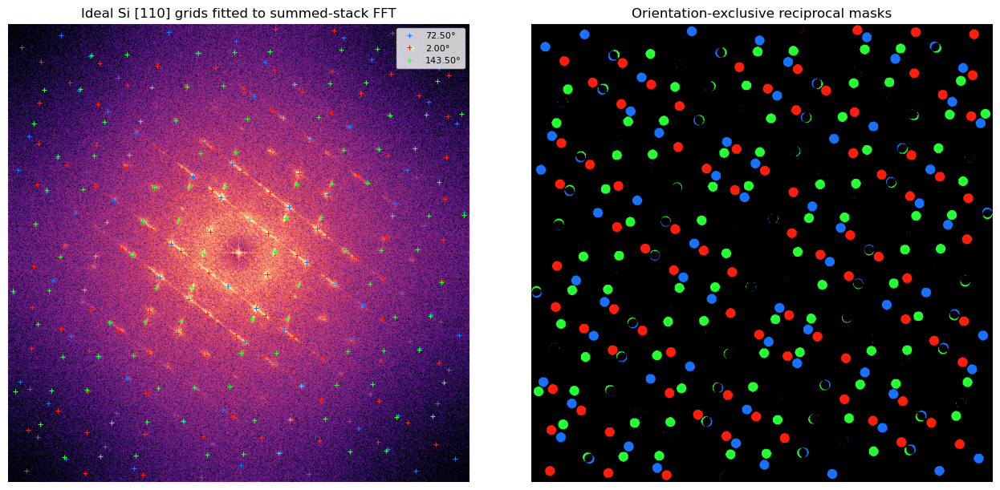

In [34]:
from scipy.ndimage import maximum_filter


# Calibration and fit controls inherited from grain-boundaries.ipynb.
pixel_size_A = PIXEL_SIZE_A
d_004_A = 1.358
a_si_A = 4 * d_004_A
match_tolerance_px = 6
mask_radius_px = 8
minimum_matched_reflections = 12
minimum_relative_score = 0.15

coloring_volume = np.asarray(fixed_stack, dtype=np.float32)
fit_image = coloring_volume[-1]
height, width = fit_image.shape
centre_y, centre_x = (np.asarray(fit_image.shape) - 1) / 2
yy, xx = np.ogrid[:height, :width]

fit_fft = np.fft.fftshift(np.fft.fft2(fit_image))
fit_spectrum = np.log1p(np.abs(fit_fft))
radius_px = np.hypot(xx - centre_x, yy - centre_y)

# Detect the strongest non-central local FFT maxima.
local_maximum = maximum_filter(fit_spectrum, size=7, mode="wrap")
candidate_pixels = np.argwhere((fit_spectrum == local_maximum) & (radius_px > 8))
candidate_strength = fit_spectrum[candidate_pixels[:, 0], candidate_pixels[:, 1]]
strongest = np.argsort(candidate_strength)[-min(600, len(candidate_pixels)):]
candidate_pixels = candidate_pixels[strongest]
candidate_strength = candidate_strength[strongest]

# Allowed diamond-cubic Si [110] reciprocal points. Coordinates are physical
# reciprocal units (1/Å) along [1 -1 0] and [001].
grid_hkls, grid_reciprocal_xy = [], []
for h in range(-12, 13):
    for l in range(-12, 13):
        if h == 0 and l == 0:
            continue
        all_odd = (h % 2 != 0) and (l % 2 != 0)
        diamond_even = (h % 2 == 0) and (l % 2 == 0) and (l % 4 == 0)
        if all_odd or diamond_even:
            grid_hkls.append((h, -h, l))
            grid_reciprocal_xy.append((np.sqrt(2) * h / a_si_A, l / a_si_A))
grid_hkls = np.asarray(grid_hkls)
grid_reciprocal_xy = np.asarray(grid_reciprocal_xy)


def projected_si110_grid(angle_deg, scale_factor):
    """Return in-frame (hkl, [y, x]) sites for a rotated ideal grid."""
    angle = np.deg2rad(angle_deg)
    rotation = np.array(
        [[np.cos(angle), -np.sin(angle)],
         [np.sin(angle),  np.cos(angle)]]
    )
    reciprocal_xy = scale_factor * grid_reciprocal_xy @ rotation.T
    pixels = np.column_stack(
        (
            centre_y + reciprocal_xy[:, 1] * height * pixel_size_A,
            centre_x + reciprocal_xy[:, 0] * width * pixel_size_A,
        )
    )
    valid = (
        (pixels[:, 0] >= 7) & (pixels[:, 0] < height - 7)
        & (pixels[:, 1] >= 7) & (pixels[:, 1] < width - 7)
    )
    return grid_hkls[valid], pixels[valid]


def reciprocal_grid_score(angle_deg, scale_factor, pixels, strengths):
    """Score observed maxima near the specified ideal reciprocal grid."""
    _, targets = projected_si110_grid(angle_deg, scale_factor)
    distance2 = ((targets[:, None, :] - pixels[None, :, :]) ** 2).sum(axis=2)
    nearest = np.argmin(distance2, axis=1)
    nearest_distance2 = distance2[np.arange(len(targets)), nearest]
    matches = nearest_distance2 <= match_tolerance_px ** 2
    score = np.sum(
        strengths[nearest[matches]]
        * (1 - nearest_distance2[matches] / match_tolerance_px ** 2)
    )
    return float(score), int(matches.sum())


# Fit the dominant detector rotation and a small scale correction.
dominant_score, dominant_angle, best_scale, dominant_match_count = -np.inf, None, None, 0
for scale in np.linspace(0.90, 1.10, 11):
    for angle in np.arange(0, 180, 1):
        score, match_count = reciprocal_grid_score(
            angle, scale, candidate_pixels, candidate_strength
        )
        if score > dominant_score:
            dominant_score, dominant_angle, best_scale, dominant_match_count = (
                score, angle, scale, match_count
            )
for scale in np.linspace(best_scale - 0.015, best_scale + 0.015, 13):
    for angle in np.linspace(dominant_angle - 1, dominant_angle + 1, 41):
        score, match_count = reciprocal_grid_score(
            angle, scale, candidate_pixels, candidate_strength
        )
        if score > dominant_score:
            dominant_score, dominant_angle, best_scale, dominant_match_count = (
                score, angle, scale, match_count
            )

# Repeatedly rotate the calibrated grid against residual FFT maxima.
remaining_pixels = candidate_pixels.copy()
remaining_strength = candidate_strength.copy()
orientation_fits = []
for orientation_index in range(8):
    best_residual = (-np.inf, None, 0)
    for angle in np.arange(0, 180, 0.25):
        score, match_count = reciprocal_grid_score(
            angle, best_scale, remaining_pixels, remaining_strength
        )
        if score > best_residual[0]:
            best_residual = (score, angle, match_count)

    score, angle, match_count = best_residual
    if (
        match_count < minimum_matched_reflections
        or score < minimum_relative_score * dominant_score
    ):
        break
    hkls, grid_pixels = projected_si110_grid(angle, best_scale)
    orientation_fits.append(
        {
            "angle_deg": float(angle),
            "score": float(score),
            "relative_score": float(score / dominant_score),
            "matched_reflections": int(match_count),
            "hkls": hkls,
            "grid_pixels": grid_pixels,
        }
    )

    # Exclude all residual candidates close to this orientation's full grid.
    distance2 = (
        (remaining_pixels[:, None, :] - grid_pixels[None, :, :]) ** 2
    ).sum(axis=2)
    keep = distance2.min(axis=1) > (2 * match_tolerance_px) ** 2
    remaining_pixels = remaining_pixels[keep]
    remaining_strength = remaining_strength[keep]

if len(orientation_fits) < 2:
    raise RuntimeError("Fewer than two statistically supported lattice orientations were found.")


def reciprocal_disk_mask(points_yx, radius):
    """Draw circular masks locally, avoiding a full-frame temporary per spot."""
    mask = np.zeros((height, width), dtype=bool)
    integer_radius = int(np.ceil(radius))
    for y, x in points_yx:
        y0 = max(0, int(np.floor(y)) - integer_radius)
        y1 = min(height, int(np.floor(y)) + integer_radius + 2)
        x0 = max(0, int(np.floor(x)) - integer_radius)
        x1 = min(width, int(np.floor(x)) + integer_radius + 2)
        patch_y, patch_x = np.ogrid[y0:y1, x0:x1]
        mask[y0:y1, x0:x1] |= (
            (patch_y - y) ** 2 + (patch_x - x) ** 2 <= radius ** 2
        )
    return mask


orientation_masks = np.stack(
    [
        reciprocal_disk_mask(fit["grid_pixels"], mask_radius_px)
        for fit in orientation_fits
    ]
)

# Reflections common to multiple grids carry no orientation information.
shared_reciprocal_pixels = orientation_masks.sum(axis=0) > 1
orientation_masks &= ~shared_reciprocal_pixels[None, :, :]

grain_colors = np.array(
    [
        [0.10, 0.45, 1.00],  # dominant: blue
        [1.00, 0.12, 0.05],  # second: red
        [0.15, 1.00, 0.20],  # third: green
        [1.00, 0.25, 0.90],  # extra orientations, if statistically supported
        [1.00, 0.75, 0.05],
        [0.10, 1.00, 0.95],
        [0.75, 0.35, 1.00],
        [0.65, 1.00, 0.10],
    ],
    dtype=np.float32,
)[:len(orientation_fits)]

print(f"Fitted reciprocal scale correction: {best_scale:.4f}")
for index, fit in enumerate(orientation_fits, start=1):
    print(
        f"Orientation {index}: {fit['angle_deg']:6.2f}°, "
        f"score={fit['score']:7.2f} "
        f"({fit['relative_score']:.3f} of dominant), "
        f"matched reflections={fit['matched_reflections']}"
    )

# Show the measured spectrum, fitted grids, and orientation-exclusive masks.
fig, axes = plt.subplots(1, 2, figsize=(13, 6), constrained_layout=True)
axes[0].imshow(
    fit_spectrum,
    cmap="magma",
    vmin=np.percentile(fit_spectrum, 5),
    vmax=np.percentile(fit_spectrum, 99.9),
)
axes[0].plot(candidate_pixels[:, 1], candidate_pixels[:, 0], "w.", ms=1, alpha=0.2)
for fit, color in zip(orientation_fits, grain_colors):
    grid_pixels = fit["grid_pixels"]
    axes[0].plot(
        grid_pixels[:, 1], grid_pixels[:, 0], "+", color=color, ms=4, mew=0.8,
        label=f"{fit['angle_deg']:.2f}°",
    )
axes[0].set_title("Ideal Si [110] grids fitted to summed-stack FFT")
axes[0].legend(loc="upper right", fontsize=8)

mask_rgb = np.zeros((height, width, 3), dtype=np.float32)
for mask, color in zip(orientation_masks, grain_colors):
    mask_rgb += mask[..., None] * color
axes[1].imshow(np.clip(mask_rgb, 0, 1))
axes[1].set_title("Orientation-exclusive reciprocal masks")
for axis in axes:
    axis.set_axis_off()
plt.show()

Saved (30, 749, 753, 3) RGB stack to /home/swim/sandbox/silicon-grain-boundaries/colored_grains_by_layer.tiff


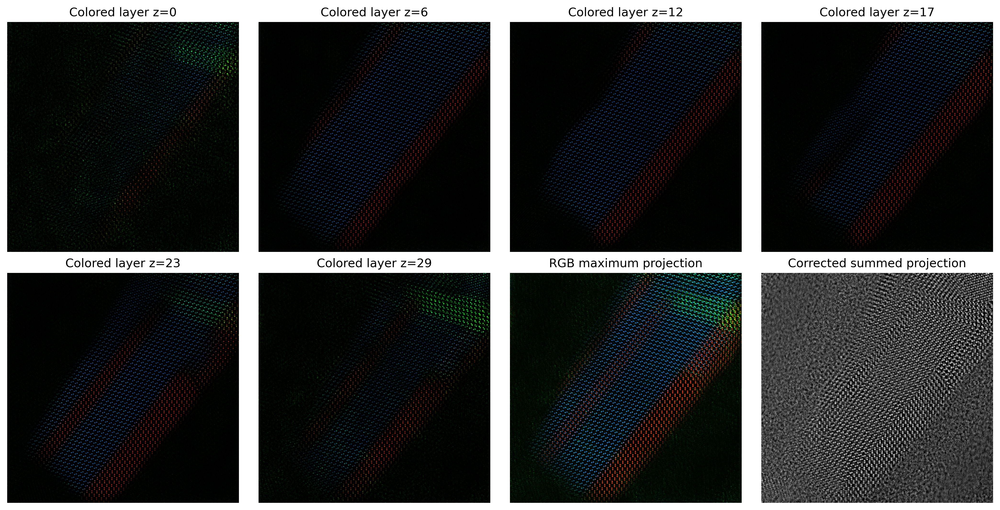

In [36]:
from scipy import fft as scipy_fft


# Reconstruct every accepted orientation independently in every z layer.
# scipy.fft keeps float32 input as complex64, limiting peak memory usage.
orientation_amplitudes = np.empty(
    (len(orientation_fits), *coloring_volume.shape), dtype=np.float32
)
for layer_index, layer in enumerate(coloring_volume):
    layer_fft = scipy_fft.fftshift(scipy_fft.fft2(layer))
    for orientation_index, mask in enumerate(orientation_masks):
        filtered = scipy_fft.ifft2(scipy_fft.ifftshift(layer_fft * mask))
        orientation_amplitudes[orientation_index, layer_index] = np.abs(filtered)

# A global robust scale per orientation preserves brightness consistency in z.
for orientation_index in range(len(orientation_fits)):
    amplitude = orientation_amplitudes[orientation_index]
    low, high = np.percentile(amplitude, (2, 99.7))
    if high <= low:
        orientation_amplitudes[orientation_index].fill(0)
    else:
        orientation_amplitudes[orientation_index] = np.clip(
            (amplitude - low) / (high - low), 0, 1
        )

# The original signal provides continuous atom support and suppresses Fourier
# ringing. Orientation contributions remain additive, so boundary atoms mix.
atom_support = np.empty_like(coloring_volume)
for layer_index, layer in enumerate(coloring_volume):
    low, high = np.percentile(layer, (5, 99.5))
    if high <= low:
        atom_support[layer_index].fill(0)
    else:
        atom_support[layer_index] = np.clip((layer - low) / (high - low), 0, 1) ** 1.5

colored_grain_float = np.zeros((*coloring_volume.shape, 3), dtype=np.float32)
for amplitude, color in zip(orientation_amplitudes, grain_colors):
    colored_grain_float += amplitude[..., None] * color
colored_grain_float = np.clip(colored_grain_float, 0, 1)
colored_grain_float *= atom_support[..., None]
colored_grain_stack = np.round(255 * colored_grain_float).astype(np.uint8)

colored_grain_path = os.path.abspath("colored_grains_by_layer.tiff")
tifffile.imwrite(
    colored_grain_path,
    colored_grain_stack,
    photometric="rgb",
    metadata={"axes": "ZYXS"},
)
print(f"Saved {colored_grain_stack.shape} RGB stack to {colored_grain_path}")

# Preview representative layers and a maximum-color projection.
preview_layers = np.unique(
    np.linspace(0, coloring_volume.shape[0] - 1, 6).round().astype(int)
)
fig, axes = plt.subplots(2, 4, figsize=(14, 7), constrained_layout=True, dpi=300)
for axis, layer_index in zip(axes.flat, preview_layers):
    axis.imshow(colored_grain_stack[layer_index])
    axis.set_title(f"Colored layer z={layer_index}")
    axis.set_axis_off()

axes.flat[-2].imshow(colored_grain_stack.max(axis=0))
axes.flat[-2].set_title("RGB maximum projection")
axes.flat[-2].set_axis_off()
axes.flat[-1].imshow(
    fit_image,
    cmap="gray",
    vmin=np.percentile(fit_image, 2),
    vmax=np.percentile(fit_image, 99.7),
)
axes.flat[-1].set_title("Corrected summed projection")
axes.flat[-1].set_axis_off()
plt.show()